In [154]:
# importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import label_binarize
from sklearn.metrics import classification_report
import joblib


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve, auc
)

#graph stylying
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 6)
warnings.filterwarnings('ignore')

print("Ready To Code")

Ready To Code


In [142]:
# importing data and displaying the data; kidney disease data

df = pd.read_csv("CKD_NHANES_2021_2023.csv")
df.head()

,participant_id,age,gender,ethnicity,education_level,poverty_income_ratio,bmi,weight_kg,height_cm,bp_systolic,...,urine_albumin,albumin_creatinine_ratio,diabetes_diagnosed,insulin_use,diabetes_pills,ever_smoked,current_smoker,egfr,ckd_stage,ckd_present
0,130378.0,43.0,Male,Non-Hispanic Asian,5.0,5.00,27.0,86.9,179.5,135.0,...,23.12,17.00,2.0,NaN,NaN,1.0,3.0,112.61,No CKD,0
1,130379.0,66.0,Male,Non-Hispanic White,5.0,5.00,33.5,101.8,174.2,121.0,...,4.25,6.64,2.0,NaN,NaN,1.0,3.0,97.98,No CKD,0
2,130380.0,44.0,Female,Other Hispanic,3.0,1.41,29.7,69.4,152.9,111.0,...,12.43,7.92,1.0,2.0,1.0,2.0,NaN,111.69,No CKD,0
3,130381.0,5.0,Female,Other/Multiracial,NaN,1.53,23.8,34.3,120.1,NaN,...,16.12,7.75,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1
4,130382.0,2.0,Male,Non-Hispanic White,NaN,3.60,NaN,13.6,NaN,NaN,...,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,Unknown,1


In [143]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 29 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   participant_id            11933 non-null  float64
 1   age                       11933 non-null  float64
 2   gender                    11933 non-null  object 
 3   ethnicity                 11933 non-null  object 
 4   education_level           7794 non-null   float64
 5   poverty_income_ratio      9892 non-null   float64
 6   bmi                       8471 non-null   float64
 7   weight_kg                 8754 non-null   float64
 8   height_cm                 8499 non-null   float64
 9   bp_systolic               7517 non-null   float64
 10  bp_diastolic              7517 non-null   float64
 11  serum_creatinine          6326 non-null   float64
 12  blood_urea_nitrogen       6326 non-null   float64
 13  albumin_serum             6366 non-null   float64
 14  phosph

In [144]:
df.shape

(11933, 29)

In [145]:
#### summing the null values
df.isnull().sum()

participant_id                  0
age                             0
gender                          0
ethnicity                       0
education_level              4139
poverty_income_ratio         2041
bmi                          3462
weight_kg                    3179
height_cm                    3434
bp_systolic                  4416
bp_diastolic                 4416
serum_creatinine             5607
blood_urea_nitrogen          5607
albumin_serum                5567
phosphorus                   5611
bicarbonate                  5608
calcium                      5571
uric_acid                    5604
urine_creatinine             3779
urine_albumin                3780
albumin_creatinine_ratio     3780
diabetes_diagnosed            193
insulin_use                 10852
diabetes_pills               9652
ever_smoked                  3798
current_smoker               8690
egfr                         5607
ckd_stage                       0
ckd_present                     0
dtype: int64

In [146]:
##Clinical Stratification Logic based on eGFR, Creatinine, ACR, and BUN
def stratify_kidney_condition(row):
    egfr = row.get('egfr', np.nan)
    creatinine = row.get('serum_creatinine', np.nan)
    acr = row.get('albumin_creatinine_ratio', np.nan)
    bun = row.get('blood_urea_nitrogen', np.nan)
    po = row.get('phosphorus', np.nan)
    ckd_present = row.get('ckd_present', 0)
    
 #Chronic Kidney Disease (CKD)
    if ckd_present == 1 or (pd.notna(egfr) and egfr < 60) or (pd.notna(acr) and acr >= 30):
        return 'Established CKD'
    
#Acute Marker / High Risk (Preserved eGFR but elevated nitrogen/creatinine)

    elif (pd.notna(creatinine) and creatinine >= 1.5) or (pd.notna(bun) and bun >= 25.0) or (pd.notna(po) and po >= 5.5):
        return 'Early High Risk'
    
    #Normal / Low Risk
    else:
        return 'Normal Low Risk'

#Apply stratification
df['kidney_strata'] = df.apply(stratify_kidney_condition, axis=1)

# Summary Table
print("--- Patient Breakdown by Clinical Strata ---")
summary_df = pd.DataFrame({
    'Count': df['kidney_strata'].value_counts(),
    'Percentage (%)': (df['kidney_strata'].value_counts(normalize=True) * 100).round(2)
})
print(summary_df)



--- Patient Breakdown by Clinical Strata ---
                 Count  Percentage (%)
Established CKD   8341           69.90
Normal Low Risk   3539           29.66
Early High Risk     53            0.44


In [147]:
def create_three_class_target(row):
    egfr = row.get('egfr', np.nan)
    creatinine = row.get('serum_creatinine', np.nan)
    acr = row.get('albumin_creatinine_ratio', np.nan)
    bun = row.get('blood_urea_nitrogen', np.nan)
    ckd_present = row.get('ckd_present', 0)
    
    # Class 2: Established CKD (Low eGFR < 60 or explicitly diagnosed CKD)
    if ckd_present == 1 or (pd.notna(egfr) and egfr < 60):
        return 2  # Established CKD
    
    # Class 1: Early High Risk (Early damage / elevated markers with preserved eGFR >= 60)
    elif (pd.notna(acr) and acr >= 30) or (pd.notna(creatinine) and creatinine >= 1.5) or (pd.notna(bun) and bun >= 25.0):
        return 1  # Early High Risk
    
    # Class 0: Low Risk (Normal eGFR, normal waste levels, normal ACR)
    else:
        return 0  # Low Risk

# Apply 3-class target transformation
df['three_class_strata'] = df.apply(create_three_class_target, axis=1)

# 2. Select Primary Care / Non-Invasive Screening Features (Prevents Diagnostic Lab Leakage)
screening_features = [
    'age', 'gender', 'ethnicity', 'poverty_income_ratio', 
    'bmi', 'weight_kg', 'height_cm', 'bp_systolic', 'bp_diastolic', 
    'diabetes_diagnosed', 'ever_smoked', 'current_smoker'
]

X = df[screening_features]
y = df['three_class_strata']  # Targets: 0 = Low Risk, 1 = Early High Risk, 2 = Established CKD

# 3. Automatically Separate Numerical and Categorical Features
num_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

# 4. Define Preprocessing Transformers
num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', num_transformer, num_features),
        ('cat', cat_transformer, cat_features)
    ]
)

# 5. Stratified Multi-Class Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Text-only distribution output
print("--- Target Class Distribution Breakdown ---")
target_dist = y.value_counts(normalize=True).rename({
    0: 'Class 0: Low Risk', 
    1: 'Class 1: Early High Risk', 
    2: 'Class 2: Established CKD'
}).map('{:.2%}'.format)

print(target_dist.to_string())
print(f"\n✓ Training features shape: {X_train.shape}")
print(f"✓ Testing features shape:  {X_test.shape}")

--- Target Class Distribution Breakdown ---
Class 2: Established CKD    69.90%
Class 0: Low Risk           29.89%
Class 1: Early High Risk     0.21%

✓ Training features shape: (9546, 12)
✓ Testing features shape:  (2387, 12)


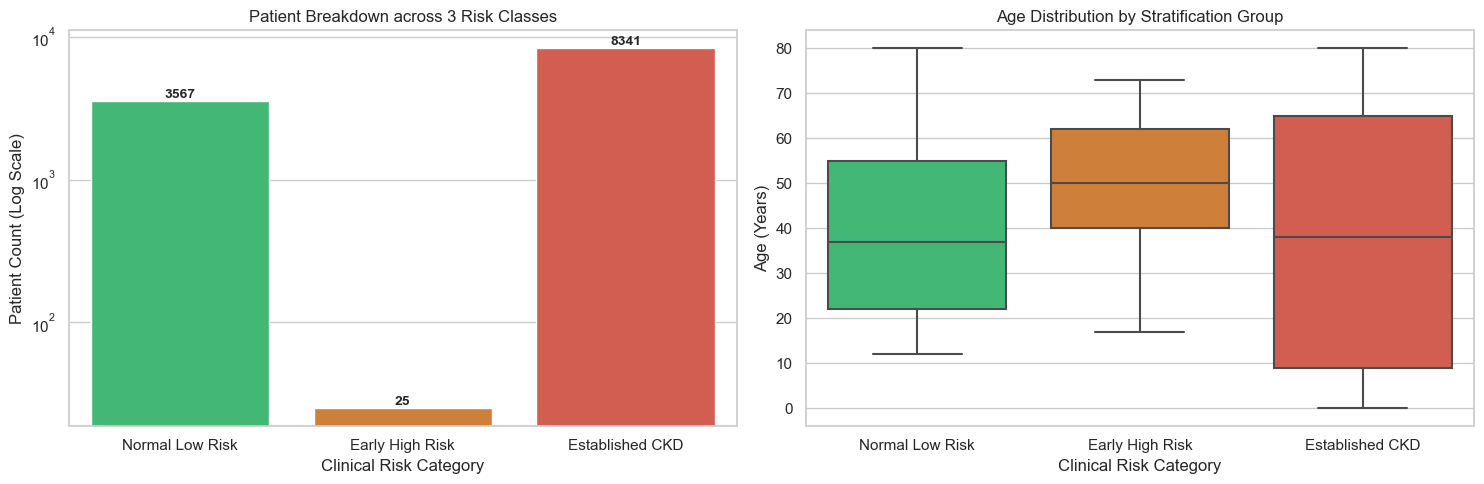

In [148]:
#Plot Stratification
# Map integer labels to descriptive clinical names for plotting
label_map = {0: 'Normal Low Risk', 1: 'Early High Risk', 2: 'Established CKD'}
df['strata_label'] = df['three_class_strata'].map(label_map)

palette_colors = {'Normal Low Risk': '#2ecc71', 'Early High Risk': '#e67e22', 'Established CKD': '#e74c3c'}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Bar Plot of Class Breakdown (Log scale to clearly see minority Class 1)
sns.countplot(data=df, x='strata_label', palette=palette_colors, ax=axes[0],
              order=['Normal Low Risk', 'Early High Risk', 'Established CKD'])
axes[0].set_title('Patient Breakdown across 3 Risk Classes')
axes[0].set_xlabel('Clinical Risk Category')
axes[0].set_ylabel('Patient Count (Log Scale)')
axes[0].set_yscale('log') # Log scale handles small count in Early High Risk

# Annotate exact patient counts on top of bars
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(f'{int(height)}',
                         (p.get_x() + p.get_width() / 2., height),
                         ha='center', va='bottom', fontsize=10, fontweight='bold')

# 2. Risk Factors Comparison: Age Distribution by Stratification Group
sns.boxplot(data=df, x='strata_label', y='age', palette=palette_colors, ax=axes[1],
            order=['Normal Low Risk', 'Early High Risk', 'Established CKD'])
axes[1].set_title('Age Distribution by Stratification Group')
axes[1].set_xlabel('Clinical Risk Category')
axes[1].set_ylabel('Age (Years)')

plt.tight_layout()
plt.show()


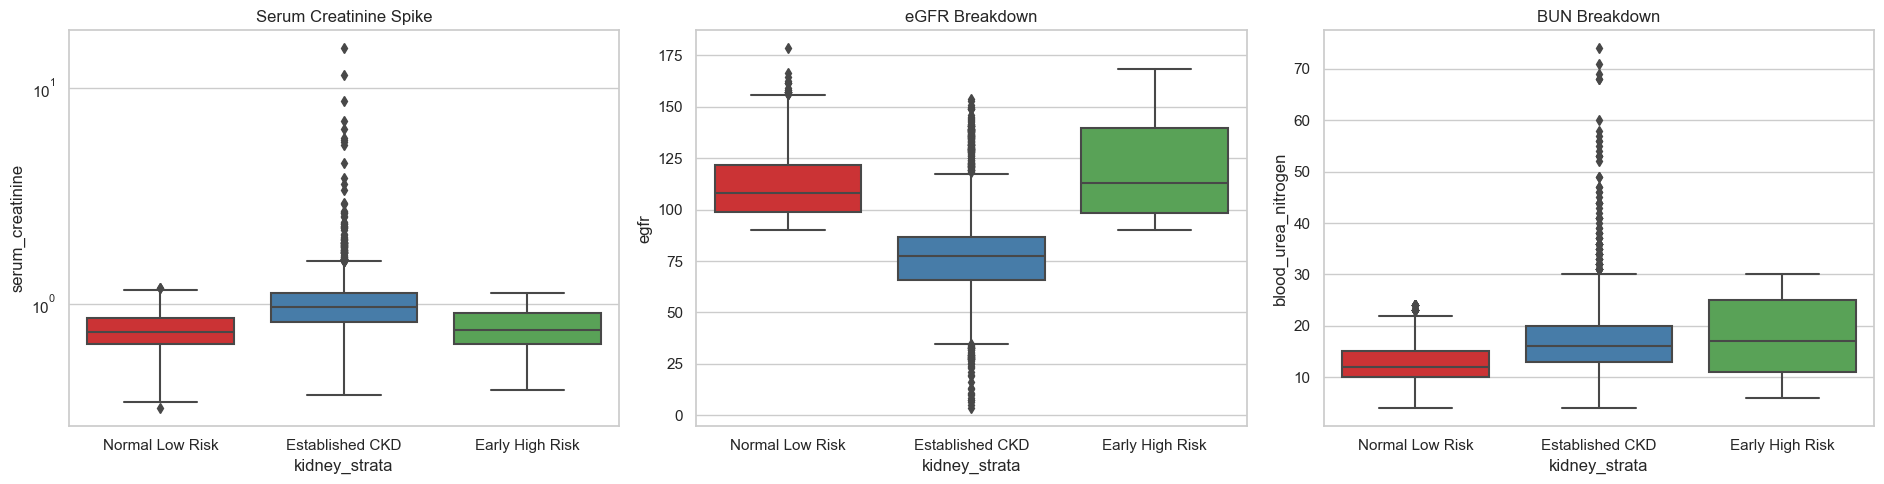

In [149]:
#ComparatIVE Biomarker Analysis across Strata
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

sns.boxplot(x='kidney_strata', y='serum_creatinine', data=df, ax=axes[0], palette='Set1')
axes[0].set_title('Serum Creatinine Spike')
axes[0].set_yscale('log')

sns.boxplot(x='kidney_strata', y='egfr', data=df, ax=axes[1], palette='Set1')
axes[1].set_title('eGFR Breakdown')

sns.boxplot(x='kidney_strata', y='blood_urea_nitrogen', data=df, ax=axes[2], palette='Set1')
axes[2].set_title('BUN Breakdown')


plt.tight_layout()
plt.show()

### Model Training & ROC Curve Comparison

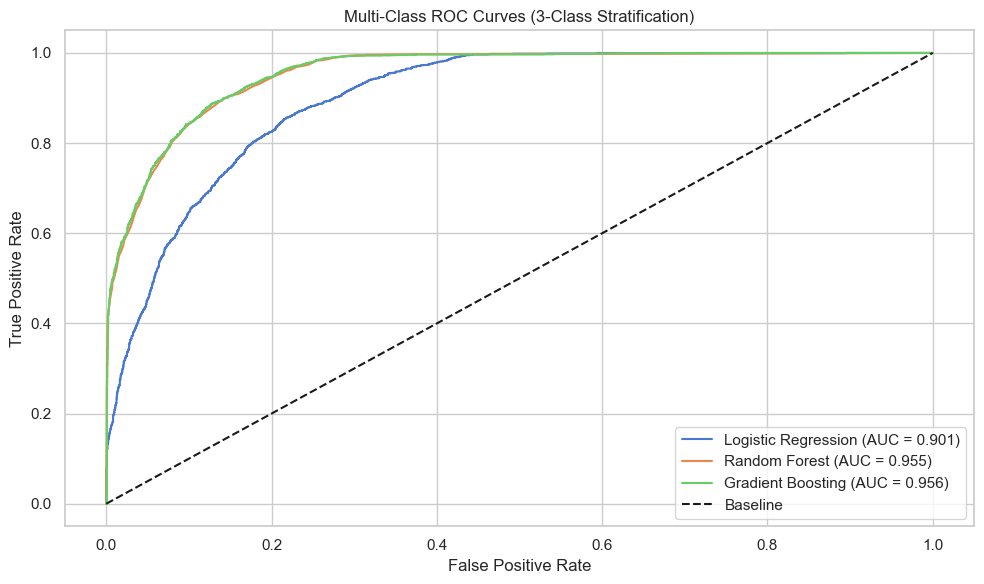

In [150]:
#Defining Model path
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

# Binarize test labels for One-vs-Rest ROC calculation across 3 classes
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])

results = []
plt.figure(figsize=(10, 6))

# Train, and Evaluate Each Model
for name, model in models.items():
    # Construct complete pipeline
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    # Train model
    pipeline.fit(X_train, y_train)
    
    # Predict classes and probability scores
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)
    
    # Micro-Average ROC Curve calculation for 3-class target
    fpr, tpr, _ = roc_curve(y_test_bin.ravel(), y_proba.ravel())
    roc_auc = auc(fpr, tpr)
    
    # Calculate overall metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    ovr_auc = roc_auc_score(y_test_bin, y_proba, average='weighted', multi_class='ovr')
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision (Weighted)': prec,
        'Recall (Weighted)': rec,
        'F1-Score (Weighted)': f1,
        'ROC-AUC (Micro-Avg)': roc_auc
    })
    
    # Plot ROC Curve line
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

# 3. Finalize ROC Plot Formatting
plt.plot([0, 1], [0, 1], 'k--', label='Baseline')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-Class ROC Curves (3-Class Stratification)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Diagnostic & Feature Importance for Best Model (Gradient Boosting)

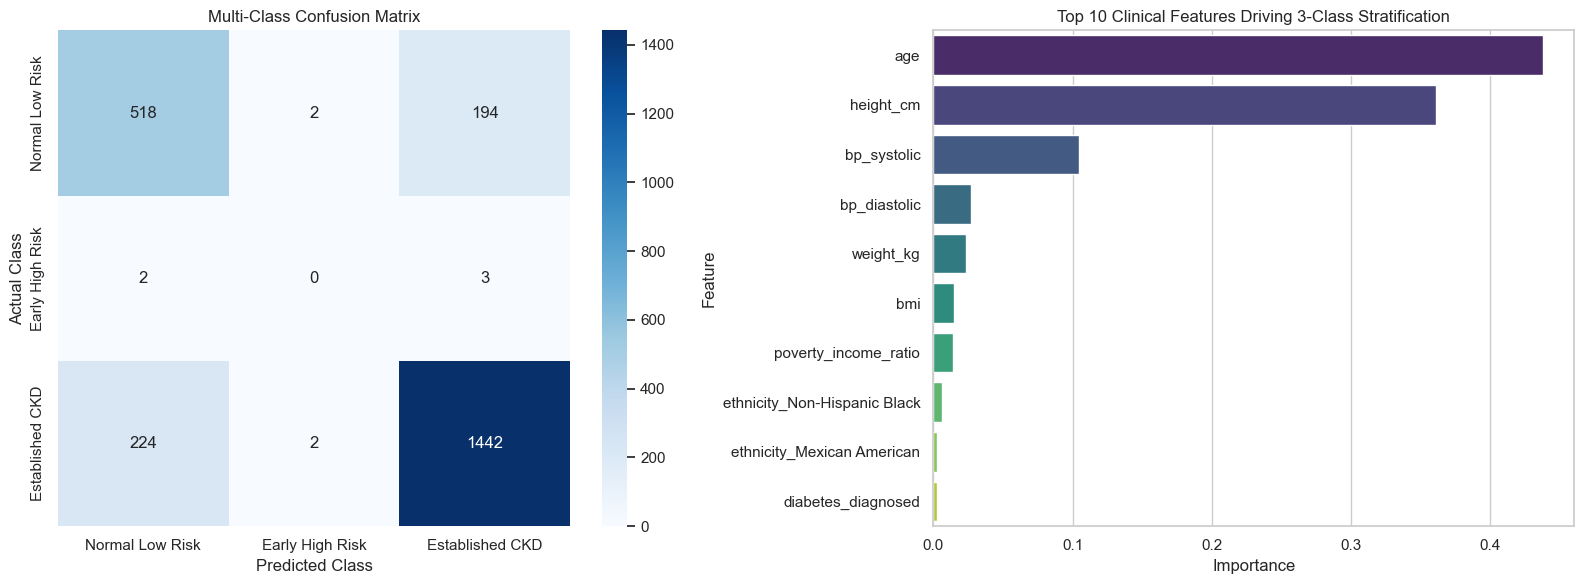

In [151]:
#Define & FIT the pipeline first
best_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(n_estimators=100, random_state=42))
])

# FIT MODEL ON TRAINING DATA (Fixes NotFittedError)
best_pipeline.fit(X_train, y_train)

# 2. Get predictions from trained pipeline
y_pred = best_pipeline.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 3. Multi-Class Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Normal Low Risk', 'Early High Risk', 'Established CKD'],
            yticklabels=['Normal Low Risk', 'Early High Risk', 'Established CKD'])
axes[0].set_title('Multi-Class Confusion Matrix')
axes[0].set_ylabel('Actual Class')
axes[0].set_xlabel('Predicted Class')

# 4. Extract Feature Importances Safely
best_model = best_pipeline.named_steps['classifier']

# Extract one-hot encoded categorical feature names safely
try:
    ohe_names = best_pipeline.named_steps['preprocessor'] \
        .named_transformers_['cat'] \
        .named_steps['onehot'] \
        .get_feature_names_out(cat_features).tolist()
except Exception:
    ohe_names = []

all_feature_names = num_features + ohe_names
importances = best_model.feature_importances_

# Create DataFrame for plotting
feature_imp_df = pd.DataFrame({
    'Feature': all_feature_names[:len(importances)],
    'Importance': importances
}).sort_values(by='Importance', ascending=False).head(10)

sns.barplot(x='Importance', y='Feature', data=feature_imp_df, ax=axes[1], palette='viridis')
axes[1].set_title('Top 10 Clinical Features Driving 3-Class Stratification')

plt.tight_layout()
plt.show()

In [153]:
#Print detailed report for each of the 3 classes
print("--- Detailed Multi-Class Classification Report ---")
target_names_list = ['Normal Low Risk', 'Early High Risk', 'Established CKD']
print(classification_report(y_test, y_pred, target_names=target_names_list, zero_division=0))

# Saved the trained pipeline to disk for future use
model_filename = 'ckd_three_class_pipeline.pkl'
joblib.dump(best_pipeline, model_filename)

print(f"\n✓ Best model pipeline successfully saved to '{model_filename}'!")

--- Detailed Multi-Class Classification Report ---
                 precision    recall  f1-score   support

Normal Low Risk       0.70      0.73      0.71       714
Early High Risk       0.00      0.00      0.00         5
Established CKD       0.88      0.86      0.87      1668

       accuracy                           0.82      2387
      macro avg       0.53      0.53      0.53      2387
   weighted avg       0.82      0.82      0.82      2387


✓ Best model pipeline successfully saved to 'ckd_three_class_pipeline.pkl'!
